# Notebook 01 — Introduction to Deep Learning and Neural Networks

**Learning path:** Deep Learning with TensorFlow  
**Level:** Beginner  
**Part:** Part I — Foundations of Deep Learning  
**Notebook version:** 1.0

---

## Chapter Overview

This notebook starts with the core ideas behind neural networks. By the end, you will build, train, and analyze a small neural network using TensorFlow and Keras.

Throughout this learning path, we will follow the same sequence:

1. Understand the problem and the underlying concept.
2. Examine a simple mathematical and visual representation.
3. Implement a small example that makes the idea concrete.
4. Train a practical model and analyze its results.

> **Important:** The dataset used in this chapter is synthetic. It does not represent real biological or medical observations; it is created only to demonstrate how a neural network learns.


## Notebook Roadmap

| Section | Topic |
|---|---|
| 1 | Learning objectives and prerequisites |
| 2 | AI, Machine Learning, and Deep Learning |
| 3 | Neural networks and artificial neurons |
| 4 | Weights, biases, and activation functions |
| 5 | Layers and neural network architecture |
| 6 | Forward propagation and the training process |
| 7 | Introduction to TensorFlow and Keras |
| 8 | Environment check and a first computational neuron |
| 9 | Building and training a neural network |
| 10 | Evaluation, visualization, and prediction analysis |
| 11 | Summary, glossary, and exercises |

### Learning Objectives

After completing this notebook, you should be able to:

- Explain the differences between Artificial Intelligence, Machine Learning, and Deep Learning.
- Identify the main components of an Artificial Neural Network.
- Explain the roles of inputs, weights, biases, activation functions, and layers.
- Describe the basic ideas behind a forward pass, a loss function, and model training.
- Explain the roles of TensorFlow and Keras in this learning path.
- Build a simple Keras model, compile and train it, and generate predictions for new data.
- Interpret basic training curves and a model decision boundary.

### Prerequisites

Basic familiarity with Python, variables, functions, arrays, and running Jupyter cells is helpful. Previous experience with Machine Learning or neural networks is not required. The mathematics needed for this path will be introduced progressively, especially in Notebook 02.

### Out of Scope for This Chapter

Detailed proofs of backpropagation, chain-rule differentiation, regularization, CNN architectures, and advanced models will be covered in later chapters. Here, we will build an intuitive overview of these ideas.


---
# 1. From Artificial Intelligence to Deep Learning

## 1.1 Artificial Intelligence (AI)

**Artificial Intelligence (AI)** is a broad area of computer science focused on building systems that can perform tasks such as reasoning, problem-solving, language understanding, planning, and pattern recognition.

## 1.2 Machine Learning (ML)

**Machine Learning (ML)** is a subfield of AI. Instead of programming every decision rule directly, an algorithm learns patterns from examples and uses those patterns to make predictions about new data.

## 1.3 Deep Learning (DL)

**Deep Learning (DL)** is a subfield of ML that uses multilayer neural networks to learn complex patterns and representations. The term *deep* generally refers to the presence of multiple computational layers in a network.

### How These Concepts Relate

Deep Learning is a subfield of Machine Learning, and Machine Learning is a subfield of Artificial Intelligence. These three terms are related, but they are not interchangeable.


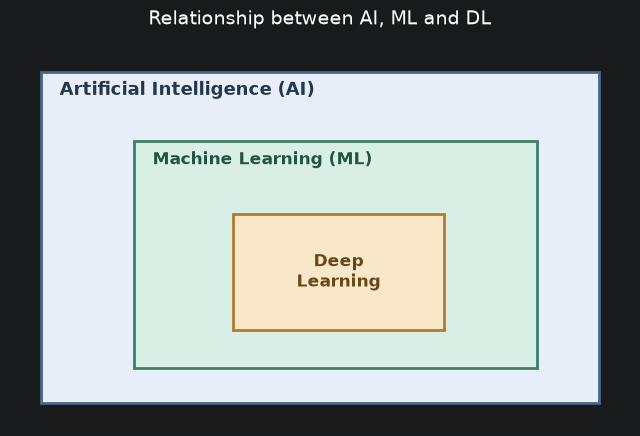

In [21]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(8, 5))
ax.add_patch(Rectangle((0.05, 0.06), 0.90, 0.86, facecolor="#e8eef7", edgecolor="#476788", linewidth=2))
ax.text(0.08, 0.86, "Artificial Intelligence (AI)", fontsize=13, weight="bold", color="#23384d")
ax.add_patch(Rectangle((0.20, 0.15), 0.65, 0.59, facecolor="#d9eee5", edgecolor="#3c8064", linewidth=2))
ax.text(0.23, 0.68, "Machine Learning (ML)", fontsize=12, weight="bold", color="#225640")
ax.add_patch(Rectangle((0.36, 0.25), 0.34, 0.30, facecolor="#f8e7c8", edgecolor="#b17b2c", linewidth=2))
ax.text(0.53, 0.40, "Deep\nLearning", ha="center", va="center", fontsize=12, weight="bold", color="#684816")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
ax.set_title("Relationship between AI, ML and DL", fontsize=14, pad=12)
plt.show()

### An Example: Distinguishing the Three Approaches

Suppose we want to detect spam emails:

- In a **rule-based system**, a programmer might define rules such as checking whether specific phrases appear in an email.
- In **Machine Learning**, an algorithm learns patterns from labeled email examples and their features.
- In **Deep Learning**, a neural network can learn more complex representations from the text or sequence of words.

This example is intended to distinguish the approaches. In practice, the best method depends on the data, dataset size, computational cost, and task objective.

## 1.4 When Is Deep Learning Useful?

Deep Learning can be useful for problems involving complex patterns and large amounts of data, including images, audio, text, and some types of biological data. However, it is not always the best choice. For small tabular datasets, classical ML methods may be simpler, faster, or equally competitive.


---
# 2. What Is an Artificial Neural Network?

## 2.1 Artificial Neural Network (ANN)

An **Artificial Neural Network (ANN)** is a computational model composed of units called artificial neurons. Neurons are connected in layers, and each connection typically has a learnable weight.

Historically, these models were inspired by simplified aspects of biological nervous systems. However, an artificial neuron is not an accurate simulation of a real biological neuron. Biological comparisons should therefore be treated as teaching analogies, not exact equivalences.

## 2.2 Components of an Artificial Neuron

A simple neuron typically performs the following operations:

1. Receive inputs: $x_1, x_2, \ldots, x_n$.
2. Multiply each input by its corresponding weight: $w_1, w_2, \ldots, w_n$.
3. Add the weighted inputs and a bias term.
4. Apply an activation function to the result.

The general equations are:

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$

$$
a = \phi(z)
$$

where:

- $x_i$: the $i$-th input
- $w_i$: the weight associated with the $i$-th input
- $b$: the bias
- $z$: the linear value before activation (pre-activation)
- $\phi$: the activation function
- $a$: the neuron's output

In Notebook 02, we will examine these equations in more detail using linear algebra and differential calculus.


In [22]:
import numpy as np

# A simple neuron with two inputs; the values are chosen only to demonstrate the calculation.
x = np.array([0.7, -1.2], dtype=float)
w = np.array([0.5, 0.8], dtype=float)
b = 0.1

z = np.dot(x, w) + b
sigmoid_output = 1.0 / (1.0 + np.exp(-z))

print(f"Inputs (x):            {x}")
print(f"Weights (w):           {w}")
print(f"Bias (b):              {b:.3f}")
print(f"Weighted sum (z):      {z:.3f}")
print(f"Sigmoid activation:    {sigmoid_output:.3f}")

Inputs (x):            [ 0.7 -1.2]
Weights (w):           [0.5 0.8]
Bias (b):              0.100
Weighted sum (z):      -0.510
Sigmoid activation:    0.375


### Interpreting the Calculation

The neuron first computes a linear combination of its inputs and then transforms that value using an activation function. The weights determine how much each input contributes to the calculation, while the bias allows the neuron's response to shift.

**Important:** Weights and biases are initialized before training and are updated during training by an optimization algorithm. This allows the model to learn relationships between inputs and outputs from data.


## 2.3 Visualizing an Artificial Neuron


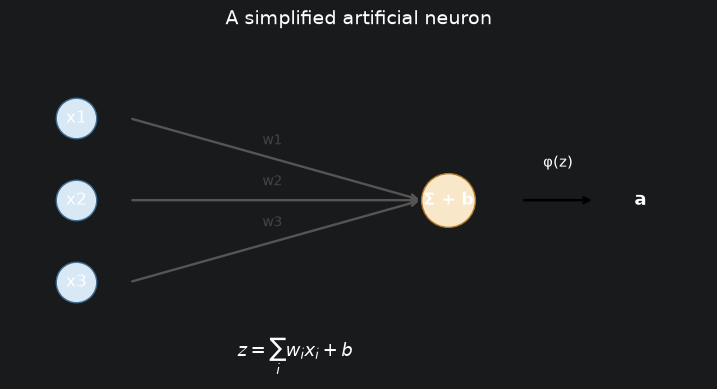

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
input_y = [0.72, 0.50, 0.28]
for i, y in enumerate(input_y, start=1):
    ax.scatter(0.10, y, s=850, color="#d9e8f5", edgecolor="#426b8f", zorder=3)
    ax.text(0.10, y, f"x{i}", ha="center", va="center", fontsize=12)
    ax.annotate("", xy=(0.62, 0.50), xytext=(0.18, y), arrowprops=dict(arrowstyle="->", lw=1.7, color="#555555"))
    ax.text(0.38, (y + 0.50) / 2 + 0.04, f"w{i}", fontsize=10, color="#444444")
ax.scatter(0.66, 0.50, s=1500, color="#f8e7c8", edgecolor="#ad782a", zorder=3)
ax.text(0.66, 0.50, "Σ + b", ha="center", va="center", fontsize=12, weight="bold")
ax.annotate("", xy=(0.88, 0.50), xytext=(0.77, 0.50), arrowprops=dict(arrowstyle="->", lw=1.8))
ax.text(0.825, 0.59, "φ(z)", ha="center", fontsize=11)
ax.text(0.94, 0.50, "a", ha="left", va="center", fontsize=13, weight="bold")
ax.text(0.43, 0.08, r"$z = \sum_i w_i x_i + b$", ha="center", fontsize=13)
ax.set_xlim(0, 1.05); ax.set_ylim(0.02, 0.95); ax.axis("off")
ax.set_title("A simplified artificial neuron", fontsize=14)
plt.show()

---
# 3. Weights, Biases, and Activation Functions

## 3.1 Weights

A **weight** determines how strongly an input contributes to a neuron's linear combination. A positive weight can move the linear output in the positive direction, while a negative weight can move it in the negative direction. The magnitude of a weight also affects the contribution. However, interpreting individual weights in a deep multilayer network is usually not as straightforward as interpreting coefficients in a simple linear model.

## 3.2 Bias

A **bias** is a learnable parameter added to the weighted sum. It allows a neuron to adjust its response boundary or level without requiring the input values themselves to shift away from zero.

## 3.3 Activation Functions

If every layer performs only a linear transformation, stacking multiple layers still results in a linear transformation. Nonlinear activation functions allow a network to learn nonlinear relationships.

### Sigmoid

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

The output lies in the interval $(0,1)$. In binary classification, a sigmoid output is often interpreted as the predicted probability of the positive class.

### Tanh

$$
\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}
$$

The output lies in the interval $(-1,1)$.

### ReLU

$$
\operatorname{ReLU}(z) = \max(0,z)
$$

ReLU is commonly used as the activation function in hidden layers of many neural networks.

### Softmax

Given a vector of scores (logits), softmax converts each component into a value between zero and one, with all output values summing to one:

$$
\operatorname{softmax}(z_i) = \frac{e^{z_i}}{\sum_j e^{z_j}}
$$

Softmax is commonly used in the output layer for single-label multiclass classification. Applying softmax alone does not guarantee that the resulting probabilities are well calibrated.


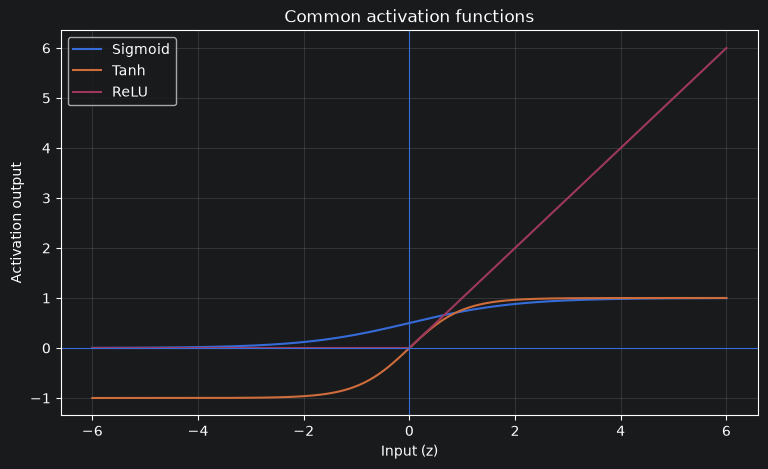

In [24]:
# Compare three commonly used activation functions.
z_values = np.linspace(-6, 6, 400)
sigmoid_values = 1 / (1 + np.exp(-z_values))
tanh_values = np.tanh(z_values)
relu_values = np.maximum(0, z_values)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(z_values, sigmoid_values, label="Sigmoid")
ax.plot(z_values, tanh_values, label="Tanh")
ax.plot(z_values, relu_values, label="ReLU")
ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)
ax.set_xlabel("Input (z)")
ax.set_ylabel("Activation output")
ax.set_title("Common activation functions")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

In [25]:
# A numerically stable softmax example (subtract the largest logit).
logits = np.array([2.0, 1.0, 0.1])
exp_values = np.exp(logits - np.max(logits))
probabilities = exp_values / exp_values.sum()

print("Logits:", logits)
print("Softmax probabilities:", np.round(probabilities, 4))
print("Sum of probabilities:", probabilities.sum())

Logits: [2.  1.  0.1]
Softmax probabilities: [0.659  0.2424 0.0986]
Sum of probabilities: 1.0


### Key Points to Remember

- Weights and biases are learnable parameters.
- Nonlinear activation functions allow a network to learn nonlinear relationships.
- ReLU is a common choice for hidden layers.
- Sigmoid is commonly used for binary outputs, while softmax is commonly used for single-label multiclass outputs. The final choice depends on the task definition and loss function.

In Notebooks 05 and 06, we will examine the relationship between activation functions, model outputs, and loss functions in more detail.


---
# 4. Layers and Neural Network Architecture

## 4.1 Architectural Components

A **feedforward neural network** is commonly described using three conceptual types of layers:

- **Input layer:** receives the input features.
- **Hidden layers:** apply learnable transformations to the data.
- **Output layer:** produces an output appropriate for the task.

In Keras models, the input can be specified with `keras.Input`. Dense layers typically connect each neuron to every output from the previous layer; this is why they are also called *fully connected* layers.

## 4.2 An Example Architecture

Suppose we have two input features, two hidden layers with 4 and 3 neurons, and one final output:

$$
2 \rightarrow 4 \rightarrow 3 \rightarrow 1
$$

This is only an example architecture. The number of layers and neurons should be selected based on the task and experiments. A larger network is not necessarily a better network.


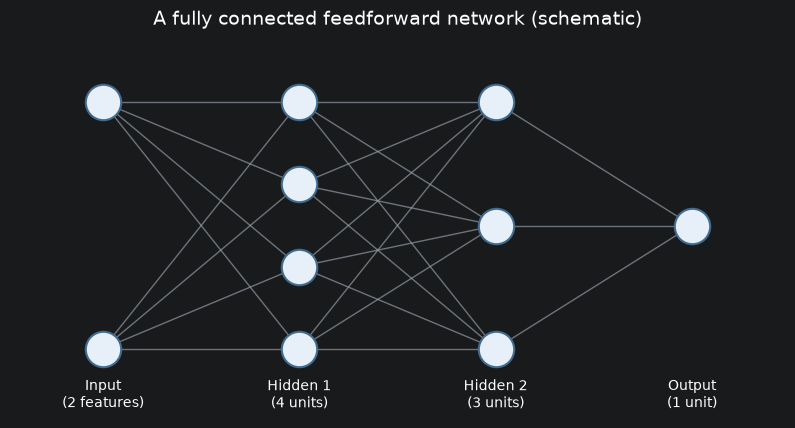

In [26]:
# Draw a schematic architecture: 2 -> 4 -> 3 -> 1.
layer_sizes = [2, 4, 3, 1]
layer_x = np.linspace(0.12, 0.88, len(layer_sizes))
positions = []

for x_pos, n_nodes in zip(layer_x, layer_sizes):
    ys = np.linspace(0.18, 0.82, n_nodes) if n_nodes > 1 else np.array([0.5])
    positions.append([(x_pos, y) for y in ys])

fig, ax = plt.subplots(figsize=(10, 5))
for layer_idx in range(len(positions) - 1):
    for x0, y0 in positions[layer_idx]:
        for x1, y1 in positions[layer_idx + 1]:
            ax.plot([x0, x1], [y0, y1], color="#9aa4ad", alpha=0.65, linewidth=1)

for layer_idx, nodes in enumerate(positions):
    for x_pos, y_pos in nodes:
        ax.scatter(x_pos, y_pos, s=650, color="#e7f0f8", edgecolor="#416b8f", linewidth=1.5, zorder=3)
    label = ["Input\n(2 features)", "Hidden 1\n(4 units)", "Hidden 2\n(3 units)", "Output\n(1 unit)"][layer_idx]
    ax.text(layer_x[layer_idx], 0.06, label, ha="center", va="center", fontsize=10)

ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
ax.set_title("A fully connected feedforward network (schematic)", fontsize=14)
plt.show()

## 4.3 Number of Parameters in a Dense Layer

For a Dense layer with $n_{in}$ input values and $n_{out}$ neurons, where each neuron has one bias, the number of parameters is:

$$
\text{Parameters} = n_{in} \times n_{out} + n_{out}
$$

The first term counts the weights, and the second term counts the biases.

For example, a layer with 2 inputs and 4 neurons has:

$$
2 \times 4 + 4 = 12
$$

This calculation applies to a standard Dense layer with `use_bias=True`.


---
# 5. Forward Propagation and the Learning Process

## 5.1 Forward Propagation (Forward Pass)

During the forward pass, data enters the network and is processed sequentially by its layers until the model produces a prediction.

Conceptually:

$$
\text{Input} \rightarrow \text{Hidden layers} \rightarrow \text{Prediction}
$$

## 5.2 Prediction and Loss

The model produces a prediction $\hat{y}$. A loss function then measures the difference between the model's prediction and the true value $y$. The choice of loss function depends on the task.

For example, binary classification commonly uses Binary Crossentropy. We will not derive this loss function in detail in this chapter.

## 5.3 Training as an Iterative Process

Neural network training repeatedly performs the following steps:

1. **Forward pass:** generate a prediction.
2. **Loss calculation:** calculate the prediction error.
3. **Backpropagation:** calculate the gradients of the loss with respect to the model parameters.
4. **Optimizer update:** update weights and biases to reduce the loss.

This cycle is repeated over data batches and multiple epochs.

### Key Terms

- **Epoch:** one complete pass through the training dataset.
- **Batch:** a subset of training examples processed in one training step.
- **Learning rate:** the step size used by the optimizer when updating parameters.
- **Optimizer:** an algorithm that uses gradients to update model parameters.

Notebook 02 covers the mathematics of gradients and the chain rule. Notebook 07 explores optimizers and training strategies in more detail.


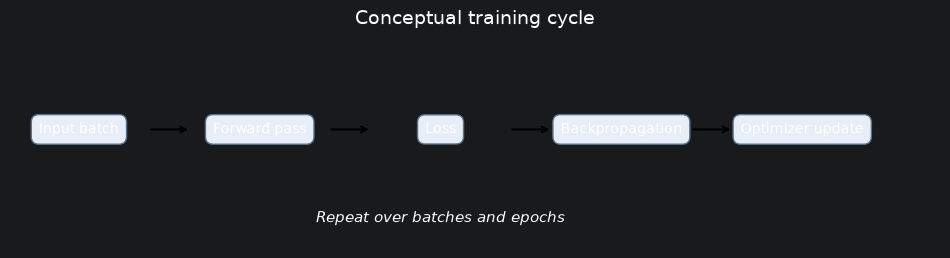

In [27]:
# Draw a schematic training cycle; this is a conceptual diagram, not a trace from a model run.
steps = ["Input batch", "Forward pass", "Loss", "Backpropagation", "Optimizer update"]
fig, ax = plt.subplots(figsize=(12, 2.8))
for i, label in enumerate(steps):
    x_pos = 0.08 + i * 0.21
    ax.text(x_pos, 0.55, label, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.55", facecolor="#e8eef7", edgecolor="#56738f"))
    if i < len(steps) - 1:
        ax.annotate("", xy=(x_pos + 0.13, 0.55), xytext=(x_pos + 0.08, 0.55),
                    arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(0.50, 0.12, "Repeat over batches and epochs", ha="center", fontsize=11, style="italic")
ax.set_xlim(0, 1.08); ax.set_ylim(0, 1); ax.axis("off")
ax.set_title("Conceptual training cycle", fontsize=14)
plt.show()

---
# 6. TensorFlow and Keras

## 6.1 What Is TensorFlow?

**TensorFlow** is an open-source framework for numerical computation and for building, training, and running machine learning models. It provides tensor operations, differentiable computations, model execution, and tools for development and deployment.

## 6.2 What Is Keras?

**Keras** is a high-level API for building and training deep learning models. In this learning path, we will use the Keras interface available in the TensorFlow ecosystem:

```python
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
```

This approach lets us learn model-building concepts through the relatively simple Keras API while retaining access to lower-level TensorFlow capabilities whenever they are needed in later chapters.

## 6.3 Why Start with Keras Sequential?

`Sequential` is suitable for models in which layers are arranged in a simple linear stack and each layer has one main input and one main output. For models with multiple inputs or outputs, parallel branches, or more complex connections, the Functional API is more suitable.

In Notebook 03, we will study the Sequential API, Functional API, and Model Subclassing separately.

### Official Resources

- [TensorFlow — Beginner quickstart](https://www.tensorflow.org/tutorials/quickstart/beginner)
- [Keras — The Sequential model](https://keras.io/guides/sequential_model/)
- [Keras — Activation functions](https://keras.io/api/layers/activations/)


## 6.4 Preparing the Runtime Environment

For this learning path, TensorFlow dependencies are recorded in a separate requirements file. We will not hard-code package versions inside the notebook so that the actual runtime environment remains visible and easy to inspect.

**Suggested environment:** Python 3.10–3.13 and TensorFlow 2.21.x, installed with `pip` in a dedicated virtual environment. The official installation guide may change as new versions are released; check the current TensorFlow installation compatibility information before creating a new environment.

Run the following commands in a terminal or PowerShell session after activating your virtual environment:

```bash
python -m pip install --upgrade pip
python -m pip install -r requirements-notebook01.txt
```

**Windows note:** Recent TensorFlow versions support CPU execution on native Windows. For NVIDIA GPU support with recent versions, the official Windows route is generally WSL2. A GPU is not required for this notebook; CPU execution is sufficient.

Official guide: [Install TensorFlow with pip](https://www.tensorflow.org/install/pip)


In [28]:
# Inspect the installed versions and available devices.
import sys
import numpy as np
import matplotlib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("TensorFlow:", tf.__version__)
print("Keras API:", getattr(keras, "__name__", "tf.keras"))
print("Available devices:", tf.config.list_physical_devices())

Python: 3.11.0
NumPy: 2.4.6
Matplotlib: 3.11.1
TensorFlow: 2.21.0
Keras API: keras._tf_keras.keras
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


If the previous cell runs without errors, the environment is ready. If TensorFlow is not installed or the import fails, first check the Python version, the active virtual environment, and the installed dependencies. Not detecting a GPU does not prevent you from completing this chapter.


---
# 7. Building Your First Neural Network with TensorFlow/Keras

In this section, we will create a simple binary classification problem. The data are generated synthetically using the two-moons pattern, which has a nonlinear decision boundary.

**Problem definition:** Given two numerical features, the model must assign each sample to one of two classes.

- **Input:** two numerical features.
- **Output:** one value between zero and one from a sigmoid activation.
- **Label:** zero or one.
- **Task type:** binary classification.

This dataset is only a teaching example and must not be interpreted as representing a real medical or biological problem.


In [29]:
def make_two_moons(n_samples=1200, noise=0.16, seed=42):
    """Generate a small two-moons dataset using NumPy only."""
    rng = np.random.default_rng(seed)
    n_class_0 = n_samples // 2
    n_class_1 = n_samples - n_class_0

    theta_0 = rng.uniform(0, np.pi, n_class_0)
    theta_1 = rng.uniform(0, np.pi, n_class_1)

    moon_0 = np.column_stack([np.cos(theta_0), np.sin(theta_0)])
    moon_1 = np.column_stack([1 - np.cos(theta_1), 0.5 - np.sin(theta_1)])

    X = np.vstack([moon_0, moon_1])
    X += rng.normal(0, noise, size=X.shape)
    y = np.concatenate([
        np.zeros(n_class_0, dtype=np.float32),
        np.ones(n_class_1, dtype=np.float32)
    ])

    order = rng.permutation(n_samples)
    X = X[order].astype(np.float32)
    y = y[order].reshape(-1, 1)
    return X, y

X, y = make_two_moons()
print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Class counts:", np.unique(y, return_counts=True))

Feature matrix shape: (1200, 2)
Label array shape: (1200, 1)
Class counts: (array([0., 1.], dtype=float32), array([600, 600]))


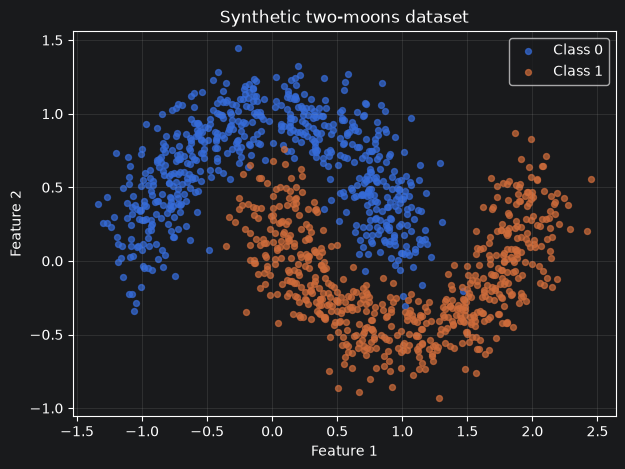

In [30]:
fig, ax = plt.subplots(figsize=(7, 5))
for class_value, label in [(0, "Class 0"), (1, "Class 1")]:
    mask = y[:, 0] == class_value
    ax.scatter(X[mask, 0], X[mask, 1], s=18, alpha=0.7, label=label)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Synthetic two-moons dataset")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 7.1 Splitting the Data (Train / Validation / Test)

The three subsets have different roles:

- **Training set:** used to learn the model parameters.
- **Validation set:** used to monitor performance during development and select model settings.
- **Test set:** held out for final evaluation on data that was not used for model selection.

In this example, we use a random split. In real medical or biological studies, if multiple samples come from the same patient or individual, splitting should usually be performed at the patient or individual level. This prevents samples from the same person from appearing in both the training and test sets.


In [31]:
# Randomly split the data using a fixed seed.
rng = np.random.default_rng(123)
indices = rng.permutation(len(X))

n_train = int(0.70 * len(X))
n_val = int(0.15 * len(X))
train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]

X_train_raw, y_train = X[train_idx], y[train_idx]
X_val_raw, y_val = X[val_idx], y[val_idx]
X_test_raw, y_test = X[test_idx], y[test_idx]

print("Train:", X_train_raw.shape, y_train.shape)
print("Validation:", X_val_raw.shape, y_val.shape)
print("Test:", X_test_raw.shape, y_test.shape)

Train: (840, 2) (840, 1)
Validation: (180, 2) (180, 1)
Test: (180, 2) (180, 1)


## 7.2 Standardizing the Features

We standardize the features using the mean and standard deviation calculated from the training set:

$$
x_{scaled} = \frac{x - \mu_{train}}{\sigma_{train}}
$$

**Important rule:** Preprocessing parameters (such as the mean and standard deviation) must be estimated using training data only. The same parameters are then applied to the validation and test sets. Fitting preprocessing steps using validation or test information can cause data leakage.


In [32]:
train_mean = X_train_raw.mean(axis=0)
train_std = X_train_raw.std(axis=0)
train_std = np.where(train_std == 0, 1.0, train_std)

X_train = ((X_train_raw - train_mean) / train_std).astype(np.float32)
X_val = ((X_val_raw - train_mean) / train_std).astype(np.float32)
X_test = ((X_test_raw - train_mean) / train_std).astype(np.float32)

print("Training means after scaling:", X_train.mean(axis=0).round(3))
print("Training stds after scaling:", X_train.std(axis=0).round(3))

Training means after scaling: [ 0. -0.]
Training stds after scaling: [1. 1.]


## 7.3 Building the Model Architecture

Our model contains the following layers:

1. An input layer with two features.
2. A Dense layer with 16 neurons and ReLU activation.
3. A Dense layer with 8 neurons and ReLU activation.
4. An output layer with one neuron and sigmoid activation.

The sigmoid output is a value between zero and one. In this example, we treat it as the model's score or predicted probability for Class 1.


In [33]:
# Set random seeds to improve reproducibility of initialization and stochastic operations.
keras.utils.set_random_seed(42)

model = keras.Sequential(
    [
        keras.Input(shape=(2,), name="input_features"),
        layers.Dense(16, activation="relu", name="hidden_1"),
        layers.Dense(8, activation="relu", name="hidden_2"),
        layers.Dense(1, activation="sigmoid", name="binary_output"),
    ],
    name="first_neural_network",
)

model.summary()

Model: "first_neural_network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ binary_output (Dense)           │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

### Checking the Number of Parameters

For this architecture:

- First layer: $2 \times 16 + 16 = 48$ parameters
- Second layer: $16 \times 8 + 8 = 136$ parameters
- Output layer: $8 \times 1 + 1 = 9$ parameters

Total: $48 + 136 + 9 = 193$ trainable parameters.

We used `model.summary()` to verify the number of parameters and the output shape of each layer. A value of `None` in the batch dimension means that the model can accept batches containing different numbers of samples.


## 7.4 Compiling the Model

Before training, we need to specify:

- **Optimizer:** the method used to update model parameters. Here, we use Adam.
- **Loss:** the quantity the model attempts to minimize during training. Here, we use Binary Crossentropy.
- **Metrics:** the metrics reported for monitoring. Here, we use Accuracy.

Accuracy is the proportion of correctly classified samples. For imbalanced problems or tasks where errors have different costs, accuracy alone is insufficient. We will study more informative metrics in Notebook 05.


In [34]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

## 7.5 Training the Model

The `fit()` method runs the training process. We also pass validation data so that validation loss and accuracy are recorded at the end of each epoch.

- `epochs=40`: the maximum number of training passes through the dataset.
- `batch_size=32`: the number of samples in each batch.
- `shuffle=True`: the order of training samples is shuffled at each epoch.

These epoch and batch-size values are example settings. For a real task, they should be selected through experimentation without using the test set.


In [35]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    shuffle=True,
    verbose=1,
)

Epoch 1/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6964 - loss: 0.6537 - val_accuracy: 0.7056 - val_loss: 0.6305
Epoch 2/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7655 - loss: 0.5862 - val_accuracy: 0.7278 - val_loss: 0.5679
Epoch 3/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8226 - loss: 0.5210 - val_accuracy: 0.8167 - val_loss: 0.5030
Epoch 4/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8440 - loss: 0.4545 - val_accuracy: 0.8389 - val_loss: 0.4394
Epoch 5/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8583 - loss: 0.3968 - val_accuracy: 0.8444 - val_loss: 0.3879
Epoch 6/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8667 - loss: 0.3542 - val_accuracy: 0.8500 - val_loss: 0.3507
Epoch 7/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8690 - loss: 0.3261 - val_accuracy: 0.8500 - val_loss: 0.3261
Epoch 8/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8762 - loss: 0.3086 - val_accuracy: 0.8611 - val_loss

## 7.6 Inspecting the Training Process

The values stored in `history.history` include loss and metric values for the training and validation sets. These curves help us understand how the model behaved during training.


Available history keys: ['accuracy', 'loss', 'val_accuracy', 'val_loss']


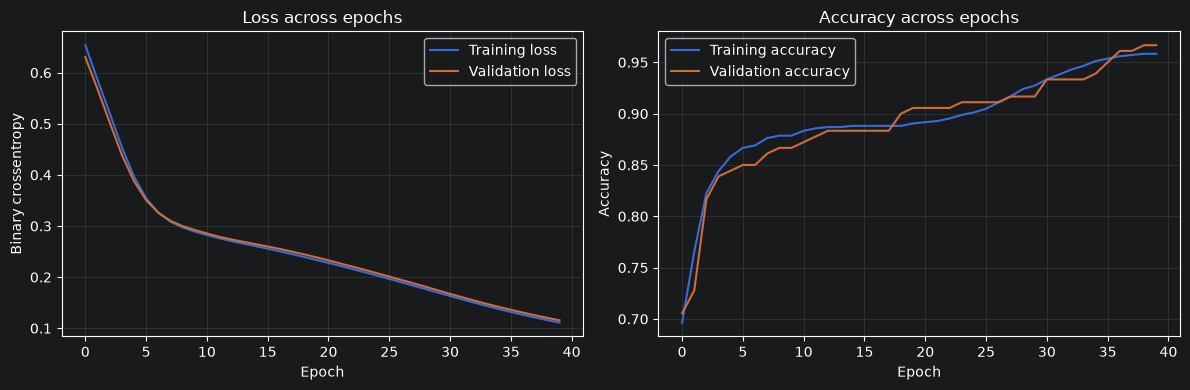

In [36]:
history_dict = history.history
print("Available history keys:", list(history_dict.keys()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_dict["loss"], label="Training loss")
axes[0].plot(history_dict["val_loss"], label="Validation loss")
axes[0].set_title("Loss across epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(history_dict["accuracy"], label="Training accuracy")
axes[1].plot(history_dict["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy across epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

### How to Read These Curves

- A decrease in training loss usually indicates that the model is fitting the training data better.
- If validation loss also decreases, this provides evidence of improvement on data that is not directly used to update the weights.
- If training loss continues to decrease while validation loss increases, overfitting may be occurring.
- If both losses remain high, the model may not have learned a sufficiently useful pattern. Possible causes include the architecture, data, features, or training configuration.

A plot alone does not provide a definitive diagnosis. In Notebook 07, we will study these patterns and strategies for addressing them in more detail.


---
# 8. Evaluation and Prediction

## 8.1 Evaluating on the Test Set

After development is complete, we evaluate final performance on the test set. This set should not have been used to choose the architecture or tune hyperparameters.


In [37]:
test_results = model.evaluate(X_test, y_test, verbose=0, return_dict=True)
print({name: round(float(value), 4) for name, value in test_results.items()})

{'accuracy': 0.9556, 'loss': 0.1071}


## 8.2 Generating Predictions

The `predict()` method returns one sigmoid output for each sample. With a threshold of 0.5, samples whose outputs are greater than or equal to 0.5 are assigned to Class 1.

This threshold is a simple convention for this exercise. In real applications, the threshold should be selected using validation data and based on the task objective and the relative costs of false positives and false negatives.


In [38]:
y_probability = model.predict(X_test, verbose=0).ravel()
threshold = 0.5
y_pred = (y_probability >= threshold).astype(int)
y_true = y_test.ravel().astype(int)

accuracy_manual = np.mean(y_pred == y_true)
print(f"Manual test accuracy at threshold={threshold:.2f}: {accuracy_manual:.4f}")

print("\nFirst 10 predictions:")
for actual, prob, predicted in zip(y_true[:10], y_probability[:10], y_pred[:10]):
    print(f"actual={actual} | predicted_probability={prob:.3f} | predicted_class={predicted}")

Manual test accuracy at threshold=0.50: 0.9556

First 10 predictions:
actual=1 | predicted_probability=0.980 | predicted_class=1
actual=1 | predicted_probability=0.520 | predicted_class=1
actual=1 | predicted_probability=0.947 | predicted_class=1
actual=1 | predicted_probability=0.969 | predicted_class=1
actual=0 | predicted_probability=0.011 | predicted_class=0
actual=1 | predicted_probability=0.994 | predicted_class=1
actual=0 | predicted_probability=0.168 | predicted_class=0
actual=0 | predicted_probability=0.060 | predicted_class=0
actual=1 | predicted_probability=0.991 | predicted_class=1
actual=0 | predicted_probability=0.064 | predicted_class=0


## 8.3 Visualizing the Decision Boundary

To inspect the pattern learned by the network, we create a grid of points in the feature space and calculate the model's predicted probability at each point. We then visualize the regions associated with different probability values.


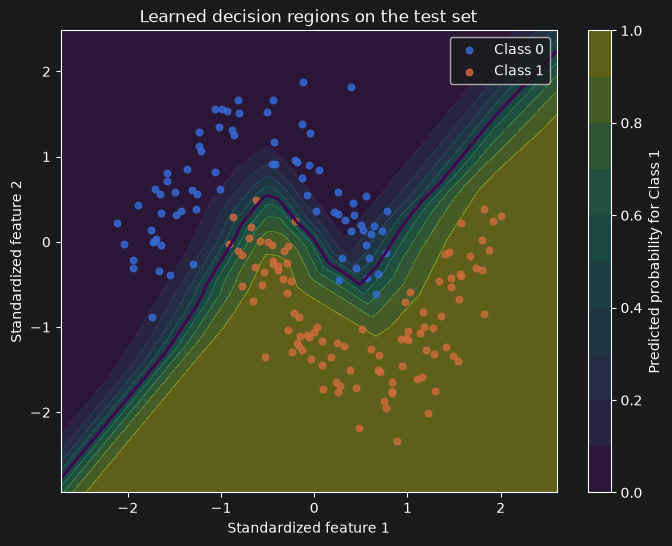

In [39]:
# Create a grid in the standardized feature space.
x_min, x_max = X_test[:, 0].min() - 0.6, X_test[:, 0].max() + 0.6
y_min, y_max = X_test[:, 1].min() - 0.6, X_test[:, 1].max() + 0.6
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 240),
    np.linspace(y_min, y_max, 240),
)
grid = np.column_stack([xx.ravel(), yy.ravel()]).astype(np.float32)
zz = model.predict(grid, verbose=0).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
contour = ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), alpha=0.35)
ax.contour(xx, yy, zz, levels=[0.5], linewidths=2)
for class_value, label in [(0, "Class 0"), (1, "Class 1")]:
    mask = y_test[:, 0] == class_value
    ax.scatter(X_test[mask, 0], X_test[mask, 1], s=22, alpha=0.8, label=label)
fig.colorbar(contour, ax=ax, label="Predicted probability for Class 1")
ax.set_xlabel("Standardized feature 1")
ax.set_ylabel("Standardized feature 2")
ax.set_title("Learned decision regions on the test set")
ax.legend()
plt.show()

### Interpreting the Decision Boundary

- The plotted boundary represents locations where the model's predicted probability for Class 1 is approximately 0.5.
- The background color represents the sigmoid output. This output is not necessarily a calibrated probability.
- Test points are shown over the model's predicted regions to make correct and difficult cases easier to inspect visually.
- A more complex decision boundary is not necessarily better. The goal is to generalize to new samples, not simply to produce a complicated boundary.

## 8.4 Inspecting a Few Errors


In [40]:
wrong = np.where(y_pred != y_true)[0]
print("Number of misclassified test samples:", len(wrong))

if len(wrong) > 0:
    show_idx = wrong[:8]
    print("Index | Actual | Probability(class 1) | Predicted")
    for i in show_idx:
        print(f"{i:5d} | {y_true[i]:6d} | {y_probability[i]:21.3f} | {y_pred[i]:9d}")
else:
    print("No test errors at the selected threshold in this run.")

Number of misclassified test samples: 8
Index | Actual | Probability(class 1) | Predicted
   11 |      1 |                 0.345 |         0
   20 |      0 |                 0.507 |         1
   50 |      0 |                 0.504 |         1
   61 |      1 |                 0.469 |         0
   94 |      0 |                 0.637 |         1
  112 |      1 |                 0.442 |         0
  124 |      0 |                 0.563 |         1
  166 |      0 |                 0.686 |         1


This simple inspection is an introduction to **error analysis**. In real projects, errors should be examined by sample characteristics, subgroups, data quality, and the consequences of model decisions. Counting errors alone is not sufficient.


---
# 9. Conceptual Summary

In this chapter, we learned that:

1. Deep Learning is a subfield of Machine Learning that uses multilayer neural networks.
2. An artificial neuron combines inputs using weights, adds a bias, and applies an activation function.
3. Hidden layers allow a network to learn more complex representations.
4. A forward pass produces a prediction, while a loss function measures the difference between the prediction and the true value.
5. During training, backpropagation calculates gradients and an optimizer updates the model parameters.
6. TensorFlow provides the computational framework, while Keras provides a high-level interface for building models in this learning path.
7. We built and trained a sample Keras model, evaluated it on a test set, and visualized its decision boundary.

### Practical Outcome of This Chapter

By the end of this chapter, you should be able to define a simple Sequential model with Dense layers, choose a loss function and optimizer, train the model with `fit()`, and inspect its outputs using `evaluate()` and `predict()`.


---
# 10. Exercises

Complete the exercises in order. Do not provide only a number or a code snippet; explain why you made each choice.

## Exercise 1 — Core Concepts

Explain the differences between AI, ML, and DL in your own words in 3–5 sentences. Give one example of each.

## Exercise 2 — Calculate an Artificial Neuron

Given the inputs $x=[1.5,-0.5]$, weights $w=[0.4,0.8]$, and bias $b=-0.2$:

1. Calculate $z$.
2. Calculate the sigmoid output using NumPy.
3. Explain how increasing the bias changes the value of $z$.

## Exercise 3 — Count the Parameters

A Dense layer has 5 inputs and 3 output neurons. Calculate the number of weights, the number of biases, and the total number of parameters.

## Exercise 4 — Change the Architecture

Modify the model in this notebook to use the following architecture and inspect the number of parameters with `model.summary()`:

$$
2 \rightarrow 32 \rightarrow 16 \rightarrow 1
$$

Does increasing the number of neurons always improve test performance? Run an experiment and explain your answer.

## Exercise 5 — Compare Activation Functions

Replace ReLU with tanh in both hidden layers. Compare the training and validation curves and the test performance. Keep the random seed and data fixed to make the comparison fair.

## Exercise 6 — Change the Decision Threshold

Convert test predictions into classes using thresholds of 0.3, 0.5, and 0.7. Report the number of positive predictions and the accuracy at each threshold. Explain why changing the threshold can change the model's decisions.

## Exercise 7 — Analyze Model Errors

Select several misclassified samples. Display the true label, predicted label, and predicted probability in a table. What can you learn from these errors?

## Optional Exercise — From Synthetic Data to a Biological Problem

Define a hypothetical binary classification problem involving two biological groups. Specify the unit of observation, the meaning of the features, how the labels are defined, and why splitting data at the patient or individual level may be necessary. Do not draw biological conclusions from the synthetic data in this notebook.


---
# 11. Self-Check Questions

Before moving on to Notebook 02, try to answer the following questions without looking back at the previous sections:

1. Why are multiple linear layers without nonlinear activations equivalent to another linear transformation?
2. What is the difference between a weight and a bias?
3. What is the role of an activation function in a neural network?
4. What is the difference between forward propagation and backpropagation?
5. Why do we keep validation and test data separate from training data?
6. Why was the standardization step fitted using only the training data?
7. What is the difference between `compile()`, `fit()`, `evaluate()`, and `predict()`?
8. Why can accuracy be misleading in a class-imbalanced problem?

If some questions are difficult, return to the relevant section. You do not need to know every mathematical detail at this stage; those details will be developed in later chapters.


---
# 12. Glossary

| Term | Brief definition |
|---|---|
| Artificial Intelligence (AI) | A broad field focused on building intelligent systems |
| Machine Learning (ML) | Learning patterns from data for prediction or decision-making |
| Deep Learning (DL) | Learning based on multilayer neural networks |
| Artificial Neural Network (ANN) | A computational model consisting of neurons and layers |
| Neuron / Unit | A computational unit within a layer |
| Weight | A parameter that controls an input's contribution to a linear combination |
| Bias | A parameter added to a linear combination |
| Activation | A function applied to a neuron's linear output |
| Layer | A group of units or operations in a network |
| Forward pass | Passing input through a model to produce an output |
| Loss | A numerical measure of prediction error |
| Backpropagation | Calculation of the loss gradients with respect to model parameters |
| Optimizer | An algorithm for updating model parameters |
| Epoch | One complete pass through the training dataset |
| Batch | A subset of samples processed in one training step |
| Training set | Data used to learn model parameters |
| Validation set | Data used to monitor performance and select model settings |
| Test set | Held-out data used for final evaluation |
| Decision threshold | A cutoff used to convert a score or probability into a class label |
| Data leakage | Use of information during model development that would not legitimately be available |


---
# 13. References and Further Reading

The following official resources are useful starting points:

1. TensorFlow. **TensorFlow 2 quickstart for beginners.**  
   https://www.tensorflow.org/tutorials/quickstart/beginner
2. TensorFlow. **TensorFlow tutorials.**  
   https://www.tensorflow.org/tutorials
3. Keras. **The Sequential model.**  
   https://keras.io/guides/sequential_model/
4. Keras. **Layer activation functions.**  
   https://keras.io/api/layers/activations/
5. TensorFlow. **Install TensorFlow with pip.**  
   https://www.tensorflow.org/install/pip

### Suggested Follow-Up Study

- In Notebook 02, we will study the mathematics of neurons, matrices, derivatives, the chain rule, and gradient descent in more depth.
- In Notebook 03, we will work with tensors, `tf.GradientTape`, the Keras APIs, and `tf.data` through practical examples.
- In Notebook 05, we will examine binary classification metrics and threshold selection in more detail.

---

**End of Notebook 01**  
Next in the learning path: **Notebook 02 — Mathematical Foundations of Neural Networks**
